<center><h1>Xie_Anna_HW5</h1></center>
<br>
<br>

Name: Anna Xie
<br>
Github Username: annajxie 
<br>
USC ID: 2277255370

## 1. Decision Trees as Interpretable Models

Import packages

In [4]:
# %pip install xgboost
import pandas as pd
import os
import numpy as np
import seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV, KFold
from sklearn.metrics import mean_squared_error
from xgboost import XGBRegressor
import matplotlib.pyplot as plt

### (a) Obtain Data

Get the Accute Inamations Data Set

In [5]:
# downlaod acute inflammations data
# Attribute lines:
# 	 '35,9'	Temperature of patient 	
# 	 'no'	Occurrence of nausea 	
# 	 'no'	Lumbar pain  	
# 	 'yes'	Urine pushing (continuous need for urination)  	
# 	 'yes'	Micturition pains  
# 	 'yes'	Burning of urethra, itch, swelling of urethra outlet 	
# 	 'yes'	decision: Inflammation of urinary bladder  
# 	 'no'	decision: Nephritis of renal pelvis origin
cols = ['temperature', 'nausea', 'lumbar-pain', 'urine-pushing', 'micturition-pains', 'burning-urethra', 'bladder-inflammation', 'nephritis']
path = '../data/diagnosis.data'
# print(os.getcwd())
# print(os.listdir("../data"))
df = pd.read_csv(path, header=None, encoding="utf-16", sep="\t", decimal=",", names=cols)
print(df.head())

   temperature nausea lumbar-pain urine-pushing micturition-pains  \
0         35.5     no         yes            no                no   
1         35.9     no          no           yes               yes   
2         35.9     no         yes            no                no   
3         36.0     no          no           yes               yes   
4         36.0     no         yes            no                no   

  burning-urethra bladder-inflammation nephritis  
0              no                   no        no  
1             yes                  yes        no  
2              no                   no        no  
3             yes                  yes        no  
4              no                   no        no  


### (b) Build a decision tree

depth: 3
leaves: 4
train acc: 1.0
test acc:1.0
alpha: 0.0
leaves: 4
test acc: 1.0


Text(0, 0.5, 'cv accuracy')

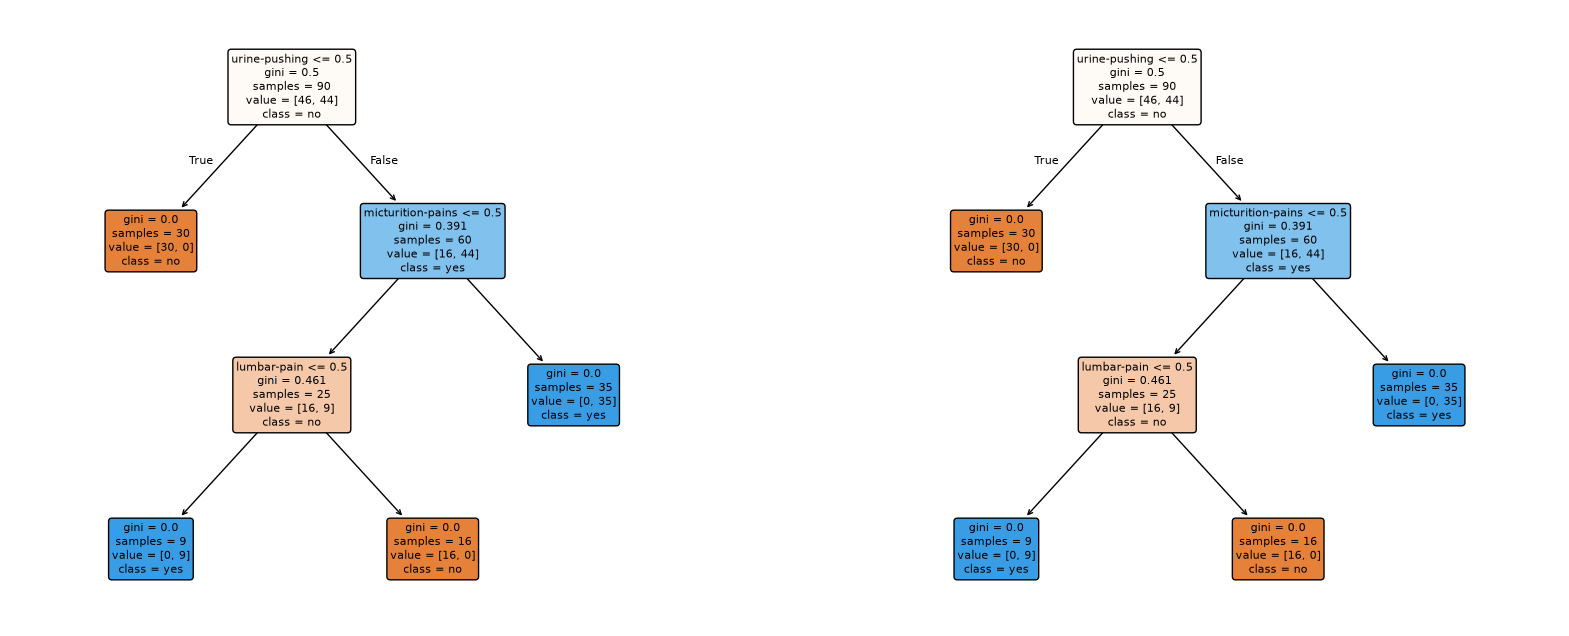

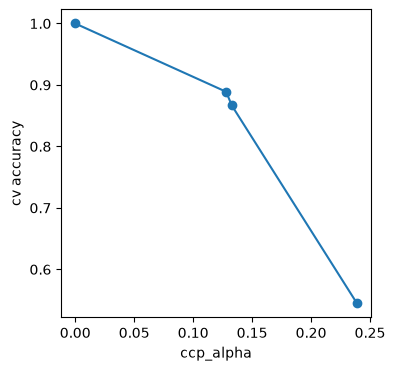

In [6]:
# two target variables: bladder-inflammation and nephritis

# some more data wrangling
# set up X and y
convert_to_num = cols[1:]
# print(target_bin)
df[convert_to_num] = df[convert_to_num].replace({"yes":1, "no":0}).astype(int)

TARGET = 'bladder-inflammation'
other = 'nephritis' if TARGET == 'bladder-inflammation' else 'bladder-inflammation'
X = df.drop(columns=[TARGET, other])
y = df[TARGET]
# print(X.shape, y.value_counts()) 
# shape = (120, 6) 120 rows, 6 cols
# 0 -> 61, 1-> 59

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.25, stratify=y, random_state=0)
tree = DecisionTreeClassifier(random_state=0).fit(X_train, y_train)
print('depth: ' + str(tree.get_depth()) + '\nleaves: ' + str(tree.get_n_leaves()) + '\ntrain acc: ' + str(tree.score(X_train, y_train)) + '\ntest acc:' + str(tree.score(X_test, y_test)))

# plot tree
fig, ax = plt.subplots(1, 2, figsize=(20, 8))
plot_tree(tree, feature_names=X.columns, class_names=['no', 'yes'], filled=True, rounded=True, ax=ax[0], fontsize=8)

# plot pruned tree
# cost-complexity pruning for minimal tree --> ccp_alpha to penalize number of leaves
# larger alpha = smaller tree
# choosen through cv on training set?
pr_path = tree.cost_complexity_pruning_path(X_train, y_train)
alphas = np.unique(pr_path.ccp_alphas)

cv = StratifiedKFold(5, shuffle=True, random_state=0)
means, stds, leaves = [], [], []
for a in alphas:
  m = DecisionTreeClassifier(ccp_alpha=a, random_state=0)
  s = cross_val_score(m, X_train, y_train, cv=cv)
  means.append(s.mean())
  stds.append(s.std())
  leaves.append(m.fit(X_train, y_train).get_n_leaves())
means, stds = np.array(means), np.array(stds)



# 1-SE rule: simplest tree => highest alpha within on SE of the best CV accuracy
best = means.argmax()
se = stds[best] / np.sqrt(cv.get_n_splits())
ok = np.where(means >= means[best] - se)[0]
alpha_star = alphas[ok.max()]
print('alpha: ' + str(alpha_star))


# final prined tree and plot this too
pruned = DecisionTreeClassifier(ccp_alpha=alpha_star, random_state=0).fit(X_train, y_train)
print('leaves: ' + str(pruned.get_n_leaves()) + '\ntest acc: ' + str(pruned.score(X_test, y_test)))

plot_tree(pruned, feature_names=X.columns, class_names=['no', 'yes'], filled=True, rounded=True, ax=ax[1], fontsize=8)
fig.savefig('../figures/full_tree.png', dpi=150, bbox_inches='tight')

# set of decision rules w high interpretability
# plot alpha?
fig, ax = plt.subplots(1,1, figsize=(4,4))
ax.plot(alphas, means, marker='o')
ax.set_xlabel('ccp_alpha')
ax.set_ylabel('cv accuracy')


### (c) Convert the decision rules

In [7]:
# set of decision rules w high interpretability
# what does high interpretability mean?

print("Full Tree:")
print(export_text(tree, feature_names=list(X_train.columns)))
print("Pruned Tree Rules:")
print(export_text(pruned, feature_names=list(X_train.columns)))

Full Tree:
|--- urine-pushing <= 0.50
|   |--- class: 0
|--- urine-pushing >  0.50
|   |--- micturition-pains <= 0.50
|   |   |--- lumbar-pain <= 0.50
|   |   |   |--- class: 1
|   |   |--- lumbar-pain >  0.50
|   |   |   |--- class: 0
|   |--- micturition-pains >  0.50
|   |   |--- class: 1

Pruned Tree Rules:
|--- urine-pushing <= 0.50
|   |--- class: 0
|--- urine-pushing >  0.50
|   |--- micturition-pains <= 0.50
|   |   |--- lumbar-pain <= 0.50
|   |   |   |--- class: 1
|   |   |--- lumbar-pain >  0.50
|   |   |   |--- class: 0
|   |--- micturition-pains >  0.50
|   |   |--- class: 1



## 2. The LASSO and Boosting for Regression

### (a) Obtain Data

In [8]:
# use first 1495 rows as training data
col_names = [
  'state', 'county', 'community', 'communityname', 'fold', 'population', 'householdsize', 'racepctblack', 'racepctWhite', 'racepctAsian',
  'racePctHisp', 'agePct12t21', 'agePct12t29', 'agePct16t24','agePct65up', 'numbUrban', 'pctUrban', 'medIncome','pctWWage','pctWFarmSelf','pctWInvInc','pctWSocSec',
  'pctWPubAsst', 'pctWRetire','medFamInc'	,'perCapInc'	,'whitePerCap'	,'blackPerCap'	,'indianPerCap'	,'AsianPerCap'	,'OtherPerCap','HispPerCap','NumUnderPov',
  'PctPopUnderPov',	'PctLess9thGrade','PctNotHSGrad','PctBSorMore'	,'PctUnemployed'	,'PctEmploy'	,'PctEmplManu'	,'PctEmplProfServ'	,'PctOccupManu',
  'PctOccupMgmtProf','MalePctDivorce'	,'MalePctNevMarr','FemalePctDiv'	,'TotalPctDiv'	,'PersPerFam'	,'PctFam2Par'	,'PctKids2Par','PctYoungKids2Par','PctTeen2Par',
  'PctWorkMomYoungKids'	,'PctWorkMom'	,'NumIlleg'	,'PctIlleg','NumImmig'	,'PctImmigRecent','PctImmigRec5','PctImmigRec8','PctImmigRec10'	,'PctRecentImmig','PctRecImmig5','PctRecImmig8'	,
  'PctRecImmig10'	,'PctSpeakEnglOnly'	,'PctNotSpeakEnglWell'	,'PctLargHouseFam'	,'PctLargHouseOccup'	,'PersPerOccupHous','PersPerOwnOccHous','PersPerRentOccHous','PctPersOwnOccup'	,
  'PctPersDenseHous','PctHousLess3BR','MedNumBR','HousVacant','PctHousOccup','PctHousOwnOcc'	,'PctVacantBoarded','PctVacMore6Mos','MedYrHousBuilt','PctHousNoPhone',
  'PctWOFullPlumb','OwnOccLowQuart','OwnOccMedVal','OwnOccHiQuart','RentLowQ','RentMedian','RentHighQ','MedRent'	,'MedRentPctHousInc','MedOwnCostPctInc',
  'MedOwnCostPctIncNoMtg','NumInShelters','NumStreet','PctForeignBorn'	,'PctBornSameState','PctSameHouse85','PctSameCity85'	,'PctSameState85','LemasSwornFT','LemasSwFTPerPop',
  'LemasSwFTFieldOps','LemasSwFTFieldPerPop','LemasTotalReq','LemasTotReqPerPop','PolicReqPerOffic','PolicPerPop','RacialMatchCommPol', 'PctPolicWhite',
  'PctPolicBlack','PctPolicHisp','PctPolicAsian','PctPolicMinor','OfficAssgnDrugUnits','NumKindsDrugsSeiz','PolicAveOTWorked','LandArea','PopDens','PctUsePubTrans',
  'PolicCars','PolicOperBudg','LemasPctPolicOnPatr','LemasGangUnitDeploy','LemasPctOfficDrugUn','PolicBudgPerPop'	,'ViolentCrimesPerPop'
]
path_com = '../data/communities.data'
df_comm = pd.read_csv(path_com, header=None, na_values='?', names=col_names)
print(df_comm.shape) #(1994,10)
# use the first 1495 as training data

training_df = df_comm[:1495]
print(training_df.shape)
testing_df = df_comm[1495:]
print(testing_df.shape)

(1994, 128)
(1495, 128)
(499, 128)


### (b) Missing values

In [9]:
# use a data imputation to deal w msising values
# nondescript that we can discard: state, county, community, communityname, fold
# print(training_df.head())
nonpred = ['state', 'county', 'community', 'communityname', 'fold']

# print(training_df.columns[:8].tolist())
# print(testing_df.columns[:8].tolist())
train = training_df.drop(columns=nonpred)
test = testing_df.drop(columns=nonpred)

# find how many mising
missing = df.isna().sum()
# print(missing[missing > 0].sort_values(ascending=False))
mostly_missing = missing[missing > 0.5 * len(df)].index
# print(mostly_missing)
train = train.drop(columns=mostly_missing)
test = test.drop(columns=mostly_missing)
# print(training_df.head())

# impute missing training data
impute = SimpleImputer(strategy='median')
X_train = train.drop(columns='ViolentCrimesPerPop')
y_train = train['ViolentCrimesPerPop']
X_test = test.drop(columns='ViolentCrimesPerPop')
y_test = test['ViolentCrimesPerPop']
X_train_imp = pd.DataFrame(impute.fit_transform(X_train), columns=X_train.columns, index = X_train.index)
X_test_imp = pd.DataFrame(impute.fit_transform(X_test), columns=X_test.columns, index=X_test.index)

print(X_train_imp.isna().sum().sum(), X_test_imp.isna().sum().sum())   # both should be 0
print(X_train_imp.shape, X_test_imp.shape)  

0 0
(1495, 122) (499, 122)


### (c) Plot a correlation matrix

In [10]:
# plot a correlation matrix for the features in the dataset
corr = X_train.corr(numeric_only=True)
print(corr)

                     population  householdsize  racepctblack  racepctWhite  \
population             1.000000      -0.040404      0.242144     -0.306023   
householdsize         -0.040404       1.000000     -0.068374     -0.243565   
racepctblack           0.242144      -0.068374      1.000000     -0.793431   
racepctWhite          -0.306023      -0.243565     -0.793431      1.000000   
racepctAsian           0.168868       0.209848     -0.104912     -0.270829   
...                         ...            ...           ...           ...   
PolicOperBudg          0.773229       0.013806      0.205796     -0.291350   
LemasPctPolicOnPatr   -0.082355      -0.070127     -0.224111      0.178714   
LemasGangUnitDeploy    0.053854       0.025162      0.043898     -0.112557   
LemasPctOfficDrugUn    0.464459      -0.086315      0.257781     -0.272366   
PolicBudgPerPop       -0.014772      -0.061034      0.083639     -0.067545   

                     racepctAsian  racePctHisp  agePct12t21  ag

### (d) Calculate the Coefficient of Variation CV

In [11]:
# calculate the coefficient of variation CV for each feature, where CV = s/m, in which s is sample standard deviation and  m is sample mean

cv_feat = X_train_imp.std(ddof=1) / X_train_imp.mean()
cv_feaet = cv_feat.replace([np.inf, -np.inf], np.nan).dropna()
print(cv_feat.sort_values(ascending=False).head(15))

PctPolicAsian          5.527059
NumStreet              4.292923
NumInShelters          3.470952
NumIlleg               3.058964
NumImmig               2.926635
LemasPctOfficDrugUn    2.552946
NumUnderPov            2.342443
LemasSwornFT           2.248042
population             2.241105
numbUrban              2.038461
HousVacant             1.968467
PolicOperBudg          1.645508
LandArea               1.645408
racePctHisp            1.612091
PctNotSpeakEnglWell    1.456618
dtype: float64


### (e) Scatter plots and box plots for highest CV features

['PctPolicAsian', 'NumStreet', 'NumInShelters', 'NumIlleg', 'NumImmig', 'LemasPctOfficDrugUn', 'NumUnderPov', 'LemasSwornFT', 'population', 'numbUrban', 'HousVacant']
In terms of feature significance, the scatter plots probably can't tell me much. Statistical significance needs to be tested with p=value and a feature that is unrelated alone can be related once compared to others and a scatter plot only compares two features w one another. Plots can be good indicators of individual feature patterns or outliers but I don't think it can establish significance.


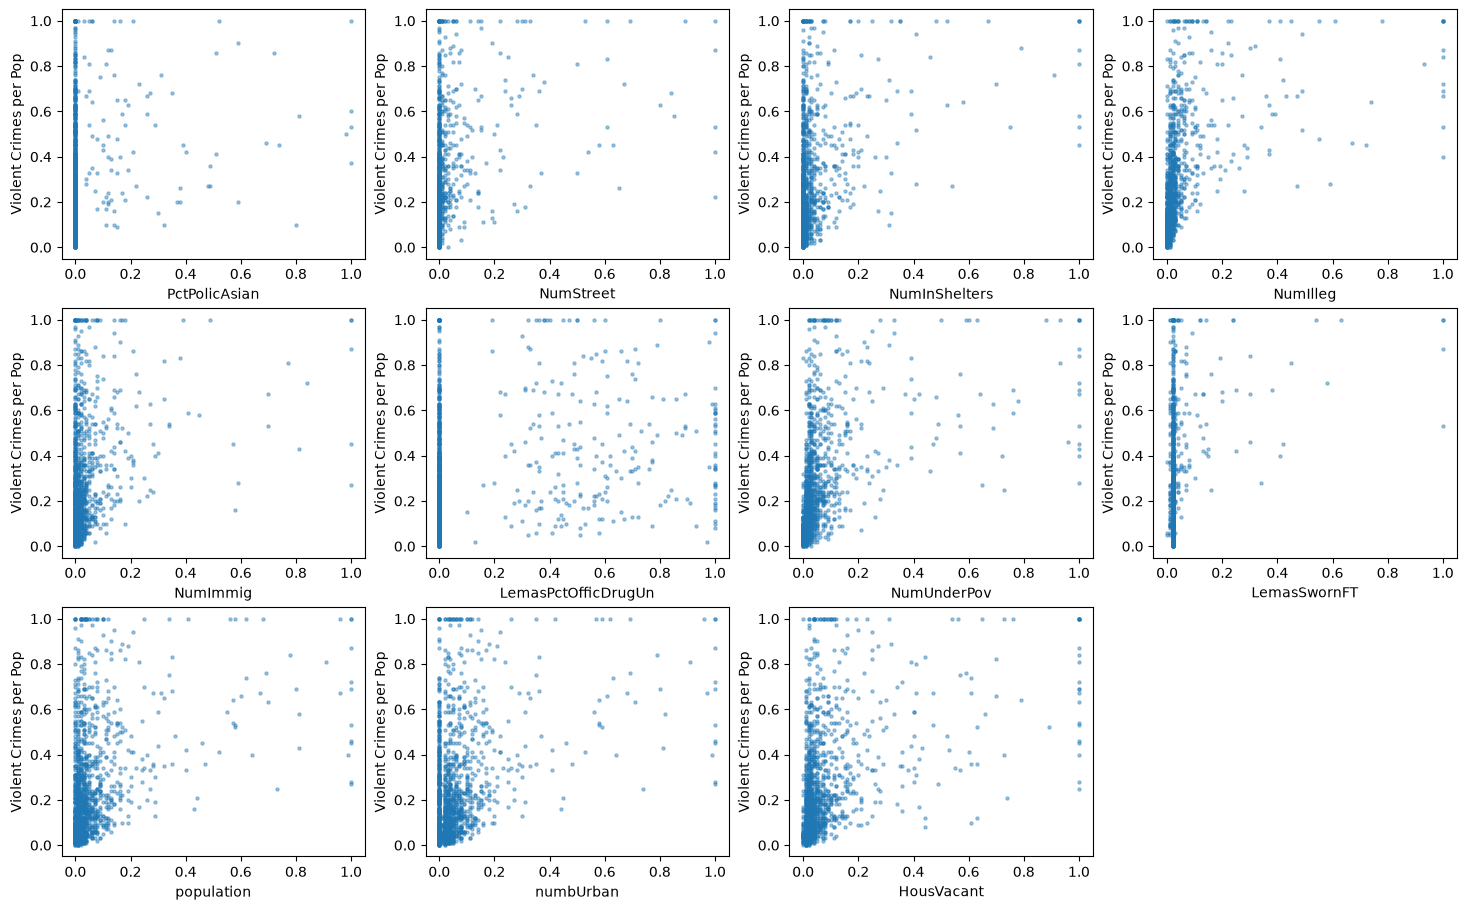

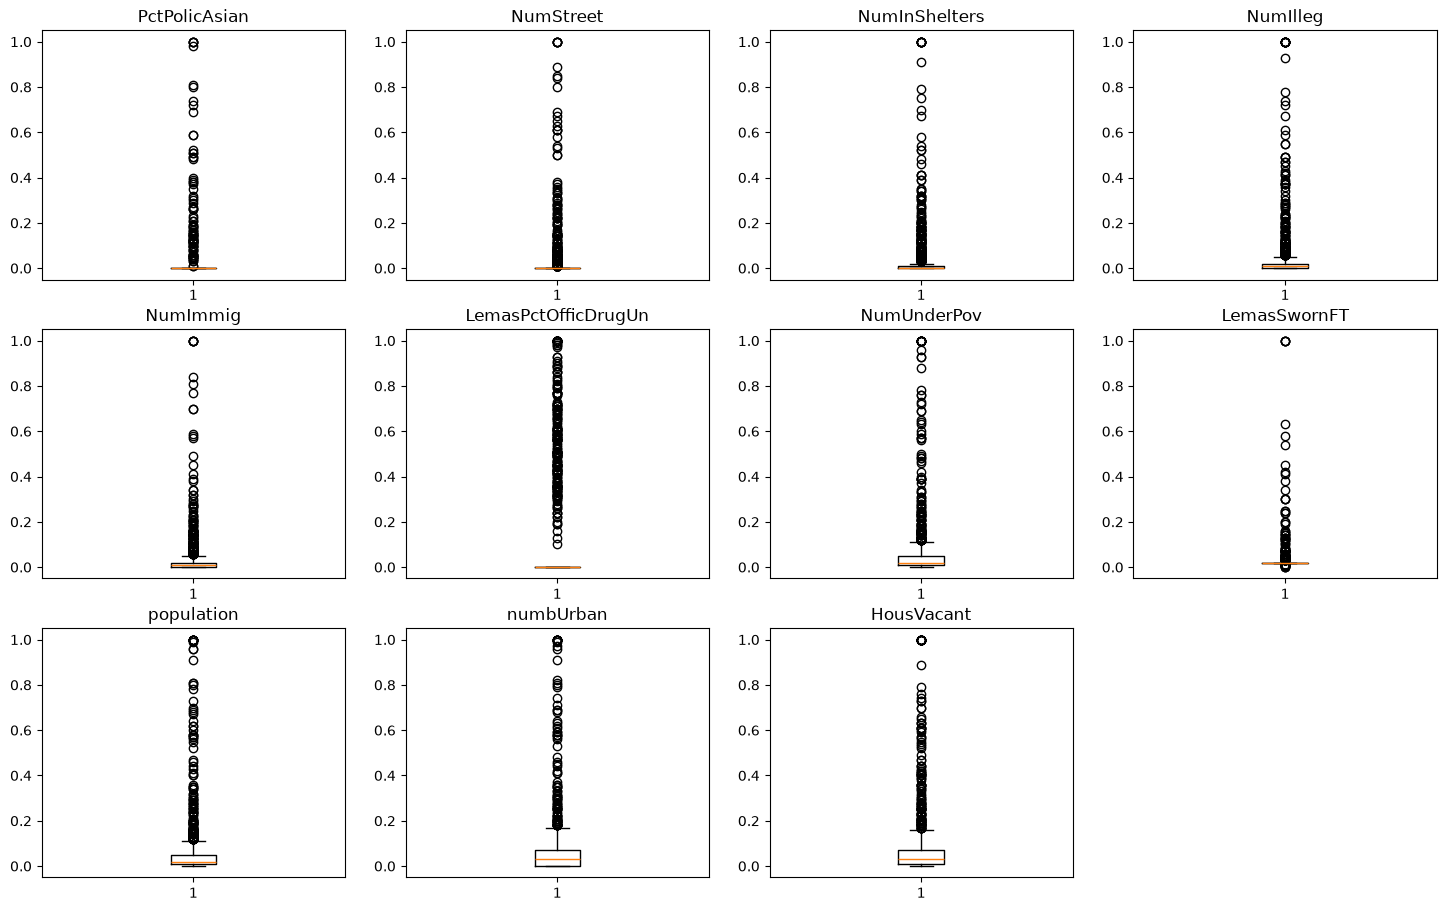

In [12]:
# Pick √128 features with highest CV 
k = int(np.floor(np.sqrt(128)))
top = cv_feat.sort_values(ascending=False).head(k).index.tolist()
print(top)
top_list = ['PctPolicAsian', 'NumStreet', 'NumInShelters', 'NumIlleg', 'NumImmig', 'LemasPctOfficDrugUn', 'NumUnderPov', 'LemasSwornFT', 'population', 'numbUrban', 'HousVacant']

# make scatter plots and box plots for them 
fig, axes = plt.subplots(3,4, figsize=(18,11))
for ax, f in zip(axes.flatten(), top):
  ax.scatter(X_train_imp[f], y_train, s=5, alpha=0.4)
  ax.set_xlabel(f)
  ax.set_ylabel('Violent Crimes per Pop')

for ax in axes.flatten()[k:]:
  ax.axis('off')
fig.savefig('highestcvfeats_scatter.png')

#box plts
fig, axes = plt.subplots(3,4, figsize=(18,11))
for ax, f in zip(axes.flatten(), top):
  ax.boxplot(X_train_imp[f].dropna())
  ax.set_title(f)
for ax in axes.flatten()[k:]:
  ax.axis('off')
fig.savefig('highestcvfeats_boxplot.png')

# can you draw conclusions about significance of those features, just by the scatter plots?
print("In terms of feature significance, the scatter plots probably can't tell me much. Statistical significance needs to be tested with p=value and a feature that is unrelated alone can be related once compared to others and a scatter plot only compares two features w one another. Plots can be good indicators of individual feature patterns or outliers but I don't think it can establish significance.")

### (f) Fit a linear model

In [13]:
# fit linear model using least squares to the training set and report the test error 

ols = LinearRegression().fit(X_train_imp, y_train)
print("Linear model test error: " + str(mean_squared_error(y_test, ols.predict(X_test_imp))))

Linear model test error: 0.01790475726712406


### (g) Fit a ridge regression model

In [14]:
# fit a ridge regression model on training set
# with b chosen by cross validation
# report test error

ridge = RidgeCV(alphas=np.logspace(-4,3,60), cv=10).fit(X_train_imp, y_train)
print('best lambda: ' + str(ridge.alpha_))
print('Test error w Ridge: ' + str(mean_squared_error(y_test, ridge.predict(X_test_imp))))

best lambda: 2.453751106639817
Test error w Ridge: 0.017495218507550158


### (h) Fit a LASSO model

In [15]:
# Fit a LASSO model on the training set, with λ chosen by cross-validation. Report
# the test error obtained, along with a list of the variables selected by the model.
# Repeat with standardized4 features. Report the test error for both cases and
# compare them.

lasso = LassoCV(cv=10, random_state=0, max_iter=100000).fit(X_train_imp, y_train)
sel = X_train_imp.columns[lasso.coef_ != 0].tolist()
print("lambda:", lasso.alpha_, "| selected:", len(sel))
print(sel)
mse_raw = mean_squared_error(y_test, lasso.predict(X_test_imp))

sc = StandardScaler().fit(X_train_imp)
Xs_tr, Xs_te = sc.transform(X_train_imp), sc.transform(X_test_imp)
lasso_s = LassoCV(cv=10, random_state=0, max_iter=100000).fit(Xs_tr, y_train)
sel_s = X_train_imp.columns[lasso_s.coef_ != 0].tolist()
print("lambda:", lasso_s.alpha_, "| selected:", len(sel_s))
print(sel_s)
mse_std = mean_squared_error(y_test, lasso_s.predict(Xs_te))

print(f"LASSO test MSE  raw: {mse_raw:.5f}   standardized: {mse_std:.5f}")


lambda: 0.00010831930127505126 | selected: 73
['racepctblack', 'racepctAsian', 'agePct12t21', 'agePct12t29', 'pctUrban', 'pctWWage', 'pctWFarmSelf', 'pctWInvInc', 'pctWSocSec', 'pctWPubAsst', 'pctWRetire', 'whitePerCap', 'blackPerCap', 'indianPerCap', 'AsianPerCap', 'OtherPerCap', 'HispPerCap', 'PctPopUnderPov', 'PctLess9thGrade', 'PctBSorMore', 'PctEmploy', 'PctEmplManu', 'PctOccupManu', 'MalePctDivorce', 'MalePctNevMarr', 'FemalePctDiv', 'PctKids2Par', 'PctYoungKids2Par', 'PctTeen2Par', 'PctWorkMom', 'NumIlleg', 'PctIlleg', 'NumImmig', 'PctImmigRec10', 'PctRecImmig10', 'PctNotSpeakEnglWell', 'PctLargHouseOccup', 'PersPerOccupHous', 'PctPersOwnOccup', 'PctPersDenseHous', 'PctHousLess3BR', 'MedNumBR', 'HousVacant', 'PctHousOccup', 'PctVacantBoarded', 'PctVacMore6Mos', 'MedYrHousBuilt', 'PctHousNoPhone', 'PctWOFullPlumb', 'OwnOccLowQuart', 'RentLowQ', 'MedRent', 'MedRentPctHousInc', 'MedOwnCostPctInc', 'MedOwnCostPctIncNoMtg', 'NumInShelters', 'NumStreet', 'PctForeignBorn', 'PctSameCity

### (i) Fit a PCR model

In [16]:
# a PCR model on the training set, with M (the number of principal components) chosen by cross-validation. Report the test error obtained

pcr = Pipeline([('pca', PCA()), ('lr', LinearRegression())])
grid = GridSearchCV(pcr, {'pca__n_components': range(1, X_train_imp.shape[1] + 1)},
                    cv=10, scoring='neg_mean_squared_error', n_jobs=-1)
grid.fit(X_train_imp, y_train)

print("best M:", grid.best_params_['pca__n_components'])
print("PCR test MSE:", mean_squared_error(y_test, grid.predict(X_test_imp)))

best M: 96
PCR test MSE: 0.018352896020135723


### (j) Fit a boosting tree

In [17]:
# n this section, we would like to fit a boosting tree to the data. As in classification
# trees, one can use any type of regression at each node to build a multivariate
# regression tree. Because the number of variables is large in this problem, one
# can use L1-penalized regression at each node. Such a tree is called L1 penalized
# gradient boosting tree. You can use XGBoost5 to fit the model tree. Determine
# α (the regularization term) using cross-validation.

xgb = XGBRegressor(
    n_estimators=300,        # number of boosting rounds
    learning_rate=0.05,
    max_depth=3,
    subsample=0.8,
    reg_lambda=1.0,          # default L2 term, held fixed
    random_state=0,
    n_jobs=-1,
)

param_grid = {"reg_alpha": [0, 0.001, 0.01, 0.1, 1, 10]}   # the L1 penalty

cv = KFold(n_splits=10, shuffle=True, random_state=0)
grid = GridSearchCV(xgb, param_grid, cv=cv,
                    scoring="neg_mean_squared_error", n_jobs=-1)
grid.fit(X_train_imp, y_train)

print("best alpha (reg_alpha):", grid.best_params_["reg_alpha"])
print("CV MSE:", -grid.best_score_)
print("XGBoost test MSE:", mean_squared_error(y_test, grid.predict(X_test_imp)))

best alpha (reg_alpha): 0
CV MSE: 0.019096244686477838
XGBoost test MSE: 0.015948057636372893
